# TP — Transfert d'apprentissage avec VGG19 et visualisation t-SNE

**Réseaux de Neurones & Deep Learning II · ÉNSP Yaoundé · Groupe 3**

**Objectif.** On utilise VGG19, entraîné sur ImageNet, comme *extracteur de caractéristiques* pour les images de produits Flipkart.
On retire les couches entièrement connectées, on résume chaque image par un vecteur obtenu par *moyenne globale* (global average pooling),
puis on projette ces vecteurs en 2D avec t-SNE. Chaque point du graphe est une image, colorée selon sa catégorie.

**La question posée.** Si les points d'une même couleur se regroupent en blocs séparés, les caractéristiques de VGG19 distinguent bien les catégories :
le modèle est exploitable pour la classification. Si les couleurs sont mélangées, il ne l'est pas, du moins pas tel quel.

Plan : 1. chargement des données · 2. modèle sans couches FC · 3. extraction des caractéristiques · 4. réduction t-SNE · 5. mesures objectives · 6. comparaison PCA / t-SNE / UMAP · 7. stabilité du t-SNE · 8. analyse par catégorie · 9. commentaire.

## 0. Bibliothèques et paramètres

In [1]:
# Installation (une seule fois, dans un terminal) :
#   python -m pip install tensorflow scikit-learn pandas matplotlib pillow openpyxl xlrd
import os, re, glob, ast, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
Image.MAX_IMAGE_PIXELS = None   # une image Flipkart dépasse 89 Mpx : jeu de données de confiance, on lève la limite

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.vgg19 import VGG19, preprocess_input

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [2]:
# ---------------------------------------------------------------
# À ADAPTER : chemin du dossier Flipkart sur votre ordinateur
# ---------------------------------------------------------------
DATA_DIR = r"C:\Users\Lenovo\Documents\mes cours\Réseaux de Neurones  Deep Learning II\Dataset+projet+prétraitement+textes+images\Flipkart"

def resoudre_chemin(chemin):
    """Retrouve un dossier même si ses accents sont encodés autrement sur le disque.

    Un dossier extrait d'un zip peut écrire « é » en deux caractères (e + accent combinant) :
    à l'écran c'est identique, mais Windows y voit un autre nom et le chemin « n'existe pas ».
    On compare donc les noms après normalisation Unicode (NFC), dossier par dossier.
    """
    if os.path.isdir(chemin):
        return chemin
    nfc = lambda s: unicodedata.normalize("NFC", s)
    lecteur, reste = os.path.splitdrive(os.path.abspath(chemin))
    courant = lecteur + os.sep
    for partie in [p for p in reste.split(os.sep) if p]:
        candidat = os.path.join(courant, partie)
        if not os.path.isdir(candidat):
            trouves = [n for n in os.listdir(courant) if nfc(n) == nfc(partie)]
            if not trouves:
                return chemin          # vraiment introuvable : on laisse l'erreur se produire plus loin
            candidat = os.path.join(courant, trouves[0])
        courant = candidat
    return courant

# Si le notebook est rangé à côté du dossier Flipkart, on l'utilise directement
if os.path.isdir("Flipkart"):
    DATA_DIR = os.path.abspath("Flipkart")
DATA_DIR = resoudre_chemin(DATA_DIR)
print("Dossier des données :", DATA_DIR, "->", "trouvé" if os.path.isdir(DATA_DIR) else "INTROUVABLE")

WEIGHTS    = "imagenet"   # poids pré-entraînés téléchargés automatiquement (~80 Mo, une seule fois)
IMG_SIZE   = 224          # taille d'entrée attendue par VGG19
BATCH_SIZE = 32
SEED       = 42
OUT_DIR    = "resultats_vgg19"   # figures et caractéristiques sauvegardées ici
os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED)
tf.random.set_seed(SEED)

def sauver_figure(nom, **options):
    """Enregistre la figure courante dans OUT_DIR.
    Si le fichier est ouvert dans une visionneuse (ex. l'application Photos), Windows refuse
    de l'écraser (OSError, Errno 22 ou 13) : on enregistre alors sous un autre nom au lieu de planter."""
    chemin = os.path.join(OUT_DIR, nom)
    try:
        plt.savefig(chemin, **options)
    except OSError:
        base, ext = os.path.splitext(chemin)
        chemin = f"{base}_{time.strftime('%H%M%S')}{ext}"
        plt.savefig(chemin, **options)
        print(f"Fichier d'origine verrouillé (ouvert ailleurs ?) : figure enregistrée sous {chemin}")


Dossier des données : C:\Users\Lenovo\Documents\mes cours\Réseaux de Neurones  Deep Learning II\Dataset+projet+prétraitement+textes+images\Flipkart -> trouvé


## 1. Chargement des données

Le jeu Flipkart est fourni sous la forme d'un **fichier de données** (Excel ou CSV, une ligne par produit) et d'un dossier d'images.
La catégorie se lit dans la colonne `product_category_tree`, qui ressemble à
`["Home Furnishing >> Curtains & Accessories >> Curtains >> ..."]` : on garde le **premier niveau** (`Home Furnishing`).

La fonction ci-dessous cherche toute seule le fichier (`.xlsx`, `.xls` ou `.csv`) et le dossier d'images, puis repère :
- la **colonne des images**, celle dont les valeurs correspondent aux noms des fichiers présents dans le dossier ;
- la **colonne des catégories** : `product_category_tree` si elle existe, sinon une colonne dont le nom évoque une catégorie (`categorie`, `category`, `label`, `classe`…).

Si votre dossier est plutôt organisé avec **un sous-dossier par catégorie**, elle le détecte aussi.
Si la détection se trompe, vous pouvez imposer les noms de colonnes avec `COL_IMAGE` et `COL_CATEGORIE`.

In [3]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
COL_IMAGE = None       # ex. "image"                  (None = détection automatique)
COL_CATEGORIE = None   # ex. "product_category_tree"  (None = détection automatique)

def premier_niveau(arbre):
    # '["A >> B >> C"]'  ->  'A'   ;   'Watches'  ->  'Watches'
    try:
        arbre = ast.literal_eval(arbre)[0]
    except Exception:
        arbre = str(arbre).strip('[]"\' ')
    return arbre.split(">>")[0].strip()

def lire_tableau(fichier):
    if fichier.lower().endswith(".csv"):
        return pd.read_csv(fichier)
    return pd.read_excel(fichier)   # .xlsx : openpyxl ; .xls : xlrd

def trouver_colonnes(tab, images):
    col_img = COL_IMAGE
    if col_img is None:
        scores = {c: tab[c].fillna("").astype(str).str.strip().map(lambda v: os.path.basename(v) in images).mean() for c in tab.columns}
        col_img = max(scores, key=scores.get)
        if scores[col_img] == 0:
            return None, None
    col_cat = COL_CATEGORIE
    if col_cat is None:
        noms = {c.lower(): c for c in tab.columns}
        col_cat = noms.get("product_category_tree") or next(
            (c for c in tab.columns if re.search(r"cat[eé]g|label|class|target|famille|type", str(c), re.I) and c != col_img), None)
    return col_img, col_cat

def charger_flipkart(racine):
    if not os.path.isdir(racine):
        raise FileNotFoundError(f"Dossier introuvable : {racine}")
    # Toutes les images présentes, indexées par nom de fichier
    images = {}
    for chemin in glob.glob(os.path.join(racine, "**", "*"), recursive=True):
        if chemin.lower().endswith(IMG_EXT):
            images.setdefault(os.path.basename(chemin), chemin)
    print(f"{len(images)} fichiers image trouvés dans le dossier.")

    # Cas 1 : un fichier Excel ou CSV qui associe chaque image à sa catégorie
    tableaux = [f for ext in ("xlsx", "xls", "csv") for f in glob.glob(os.path.join(racine, "**", f"*.{ext}"), recursive=True)
                if not os.path.basename(f).startswith("~$")]   # ignore les fichiers temporaires d'Excel ouvert
    for fichier in tableaux:
        try:
            tab = lire_tableau(fichier)
        except Exception as e:
            print(f"Lecture impossible de {os.path.basename(fichier)} : {e}")
            continue
        col_img, col_cat = trouver_colonnes(tab, images)
        if col_img is None or col_cat is None:
            continue
        df = pd.DataFrame({"image": tab[col_img].fillna("").astype(str).str.strip().map(os.path.basename),
                           "categorie": tab[col_cat].apply(premier_niveau)})
        if "product_name" in tab:
            df["product_name"] = tab["product_name"]
        df["chemin"] = df["image"].map(images)
        manquantes = df["chemin"].isna().sum()
        if manquantes:
            print(f"Attention : {manquantes} images citées dans le fichier sont absentes du dossier.")
        print(f"Fichier utilisé : {os.path.basename(fichier)} · colonne image = '{col_img}' · colonne catégorie = '{col_cat}'")
        return df.dropna(subset=["chemin"]).reset_index(drop=True)

    # Cas 2 : un sous-dossier par catégorie
    lignes = [{"image": n, "chemin": c, "categorie": os.path.basename(os.path.dirname(c))} for n, c in images.items()]
    if not lignes:
        raise FileNotFoundError("Aucune image trouvée dans ce dossier.")
    print("Pas de fichier Excel/CSV exploitable : la catégorie est lue dans le nom du sous-dossier.")
    return pd.DataFrame(lignes)

df = charger_flipkart(DATA_DIR)
CATEGORIES = sorted(df["categorie"].unique())
print(f"{len(df)} images, {len(CATEGORIES)} catégories")
df["categorie"].value_counts().to_frame("nombre d'images")

1050 fichiers image trouvés dans le dossier.


Fichier utilisé : flipkart_com-ecommerce_sample_1050.csv · colonne image = 'image' · colonne catégorie = 'product_category_tree'
1050 images, 7 catégories


,nombre d'images
categorie,
Home Furnishing,150
Baby Care,150
Watches,150
Home Decor & Festive Needs,150
Kitchen & Dining,150
Beauty and Personal Care,150
Computers,150


Un exemple d'image par catégorie, pour se faire une idée de ce que le réseau va devoir distinguer.

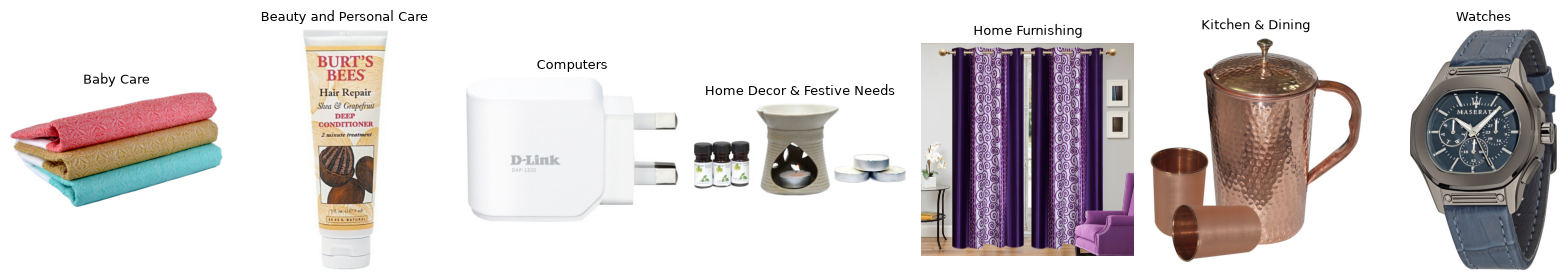

In [4]:
fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(2.3 * len(CATEGORIES), 2.9))
axes = np.atleast_1d(axes)
for ax, cat in zip(axes, CATEGORIES):
    chemin = df.loc[df["categorie"] == cat, "chemin"].iloc[0]
    ax.imshow(keras.utils.load_img(chemin))
    ax.set_title(cat, fontsize=9, wrap=True)
    ax.axis("off")
plt.tight_layout()
sauver_figure("exemples_categories.png", dpi=150)
plt.show()

## 2. VGG19 sans ses couches entièrement connectées

VGG19 se compose de 16 couches de convolution (5 blocs) suivies de 3 couches entièrement connectées (FC) qui servent à classer les 1 000 catégories d'ImageNet.
Ces couches FC sont spécialisées pour ImageNet : on les **supprime** avec `include_top=False`.

À la sortie du dernier bloc convolutif, une image de $224\times224$ est devenue un volume de $7\times7\times512$ : 512 cartes de caractéristiques de $7\times7$.
L'option `pooling="avg"` ajoute une **moyenne globale** (*global average pooling*) qui résume chaque carte par sa moyenne :

$$z_k \;=\; \frac{1}{7\times7}\sum_{i=1}^{7}\sum_{j=1}^{7} A_{i,j,k}, \qquad k = 1,\dots,512.$$

Chaque image est donc décrite par un vecteur de **512 nombres**, qui mesure à quel point chacun des 512 motifs appris sur ImageNet est présent dans l'image.
Les poids sont gelés : on n'entraîne rien, on se contente de lire ce que le réseau « voit ».

In [5]:
extracteur = VGG19(weights=WEIGHTS, include_top=False, pooling="avg",
                   input_shape=(IMG_SIZE, IMG_SIZE, 3))
extracteur.trainable = False
print("Entrée :", extracteur.input_shape, "→ sortie :", extracteur.output_shape)
print(f"Paramètres : {extracteur.count_params():,}".replace(",", " "))
print("Dernières couches :", [c.name for c in extracteur.layers[-4:]])

Entrée : (None, 224, 224, 3) → sortie : (None, 512)
Paramètres : 20 024 384
Dernières couches : ['block5_conv3', 'block5_conv4', 'block5_pool', 'global_average_pooling2d']


## 3. Extraction des caractéristiques

Chaque image est redimensionnée en $224\times224$, convertie en RVB, puis passée par `preprocess_input`, qui applique **exactement** le prétraitement utilisé
lors de l'entraînement de VGG19 (passage en BGR et soustraction de la couleur moyenne d'ImageNet). Oublier cette étape dégrade fortement les caractéristiques, sans erreur visible.

Le résultat est sauvegardé dans `resultats_vgg19/` : si vous relancez le notebook, l'extraction n'est pas refaite.

In [6]:
def lire_image(chemin):
    img = keras.utils.load_img(chemin, target_size=(IMG_SIZE, IMG_SIZE), color_mode="rgb")
    return keras.utils.img_to_array(img)

fichier_cache = os.path.join(OUT_DIR, f"caracteristiques_vgg19_{len(df)}.npz")
if os.path.exists(fichier_cache):
    cache = np.load(fichier_cache, allow_pickle=True)
    X, y = cache["X"], cache["y"].astype(str)
    print("Caractéristiques rechargées depuis", fichier_cache)
else:
    debut, morceaux = time.time(), []
    chemins = df["chemin"].tolist()
    for i in range(0, len(chemins), BATCH_SIZE):
        lot = np.stack([lire_image(c) for c in chemins[i:i + BATCH_SIZE]])
        morceaux.append(extracteur.predict(preprocess_input(lot), verbose=0))
        print(f"\r{min(i + BATCH_SIZE, len(chemins))}/{len(chemins)} images", end="")
    X, y = np.vstack(morceaux), df["categorie"].astype(str).to_numpy()
    np.savez_compressed(fichier_cache, X=X, y=y)
    print(f"\nTerminé en {time.time() - debut:.0f} s")

print("Matrice des caractéristiques :", X.shape)

Caractéristiques rechargées depuis resultats_vgg19\caracteristiques_vgg19_1050.npz
Matrice des caractéristiques : (1050, 512)


## 4. Réduction en 2D avec t-SNE

**t-SNE** (*t-distributed Stochastic Neighbor Embedding*) place chaque image sur un plan de façon à ce que deux images **proches dans l'espace à 512 dimensions restent proches en 2D**.
Elle préserve surtout le voisinage local : les groupes qu'on voit sur le graphe sont fiables, mais la distance entre deux groupes éloignés, ou la taille d'un groupe, ne s'interprètent pas.

Deux réglages :
- on applique d'abord une **ACP à 50 composantes**, pratique courante qui retire le bruit et accélère t-SNE ;
- la **perplexité** (30 ici) correspond à peu près au nombre de voisins que t-SNE cherche à respecter pour chaque point.

t-SNE est aléatoire : on fixe `random_state` pour obtenir toujours le même graphe.

In [7]:
n_comp = min(50, X.shape[0] - 1, X.shape[1])
X_pca = PCA(n_components=n_comp, random_state=SEED).fit_transform(X)
perplexite = min(30, (len(X) - 1) / 3)

tsne = TSNE(n_components=2, perplexity=perplexite, init="pca", learning_rate="auto", random_state=SEED)
X_2d = tsne.fit_transform(X_pca)
print("Projection 2D :", X_2d.shape, "· perplexité", perplexite)

Projection 2D : (1050, 2) · perplexité 30


Chaque point est une image ; sa couleur indique sa vraie catégorie. Le nom de chaque catégorie est placé au centre de son nuage.

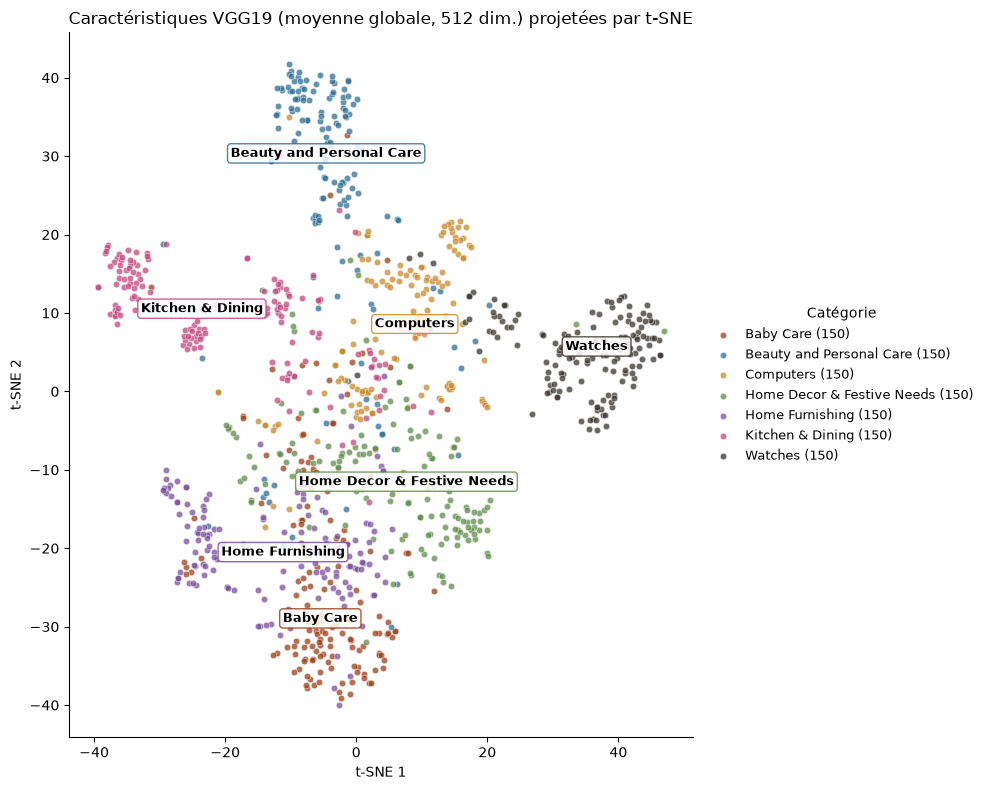

In [8]:
PALETTE = ["#9C3F17", "#2E6F95", "#C98A2B", "#5E8C4A", "#7A4E9C", "#C2477E", "#3A3530",
           "#3C9D9B", "#B5B23C", "#8C6D4F"]
couleurs = {c: PALETTE[i % len(PALETTE)] for i, c in enumerate(CATEGORIES)}

fig, ax = plt.subplots(figsize=(10, 8))
for cat in CATEGORIES:
    m = y == cat
    ax.scatter(X_2d[m, 0], X_2d[m, 1], s=22, alpha=0.75, color=couleurs[cat],
               edgecolors="white", linewidths=0.4, label=f"{cat} ({m.sum()})")
for cat in CATEGORIES:
    cx, cy = np.median(X_2d[y == cat], axis=0)
    ax.text(cx, cy, cat, fontsize=9, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=couleurs[cat], alpha=0.85))
ax.set_title("Caractéristiques VGG19 (moyenne globale, 512 dim.) projetées par t-SNE", fontsize=12)
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9, title="Catégorie")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
sauver_figure("tsne_vgg19_categories.png", dpi=200, bbox_inches="tight")
plt.show()

Pour mieux comprendre les mélanges éventuels, on affiche les images elles-mêmes à leur position t-SNE (un échantillon de 250 images), avec un cadre de la couleur de leur catégorie.

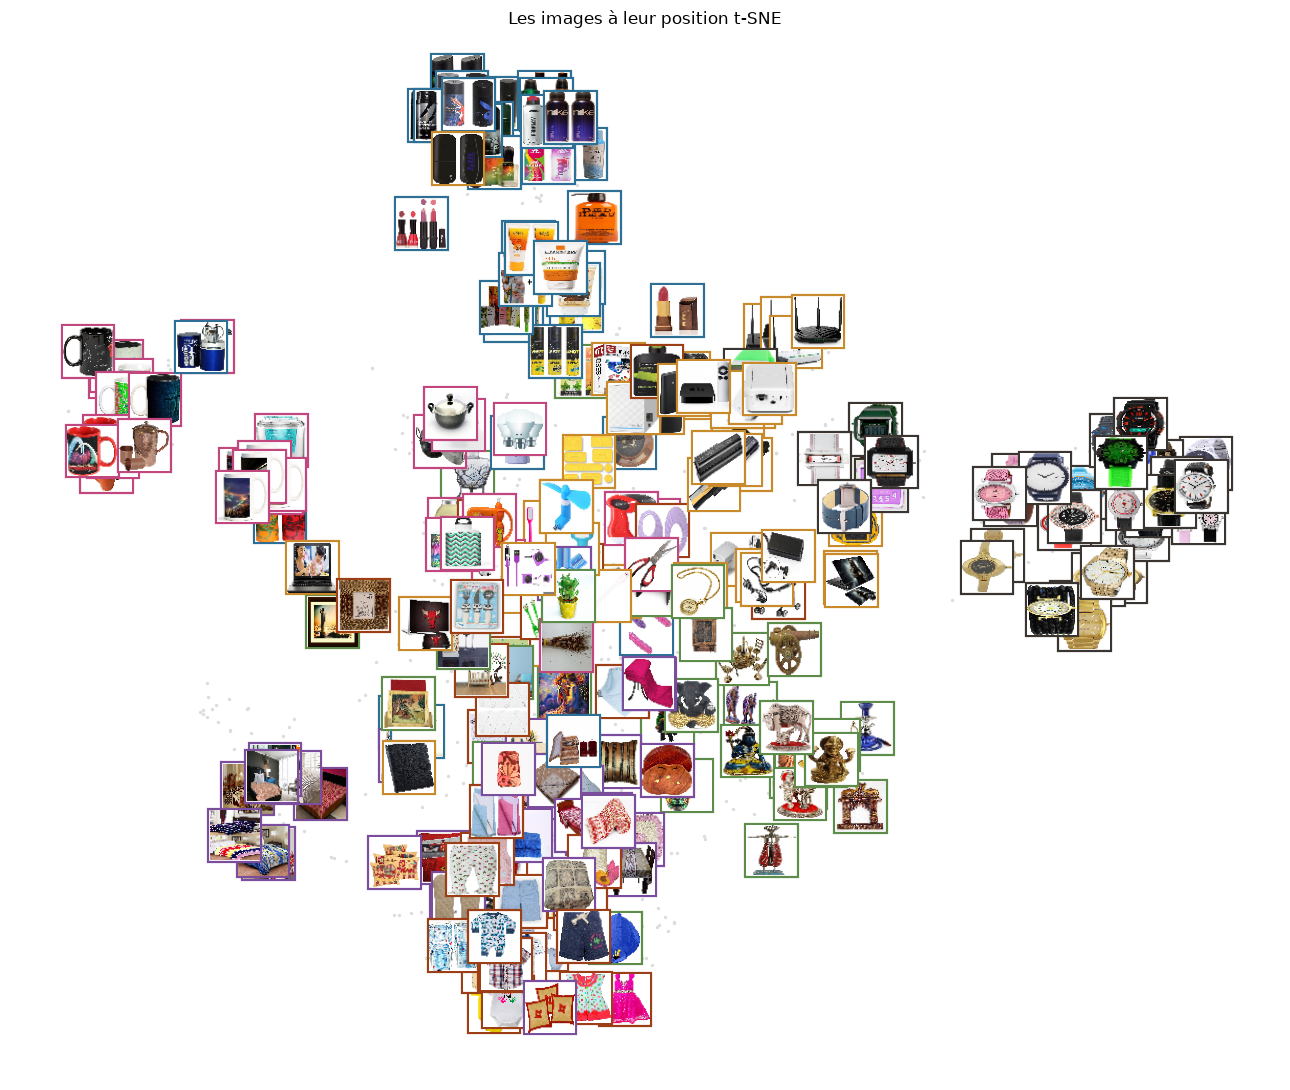

In [9]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

rng = np.random.default_rng(SEED)
idx = rng.choice(len(df), size=min(250, len(df)), replace=False)
fig, ax = plt.subplots(figsize=(13, 11))
ax.scatter(X_2d[:, 0], X_2d[:, 1], s=2, color="#dddddd")
for i in idx:
    vignette = keras.utils.load_img(df.loc[i, "chemin"], target_size=(48, 48))
    ab = AnnotationBbox(OffsetImage(np.asarray(vignette), zoom=0.75), X_2d[i], frameon=True,
                        pad=0.1, bboxprops=dict(edgecolor=couleurs[y[i]], linewidth=1.6))
    ax.add_artist(ab)
ax.set_title("Les images à leur position t-SNE", fontsize=12)
ax.axis("off")
plt.tight_layout()
sauver_figure("tsne_vgg19_vignettes.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Mesurer ce que l'on voit

Un graphe se lit à l'œil, mais quelques chiffres rendent le commentaire plus solide :

- **Pureté du voisinage** : pour chaque image, la part de ses 10 plus proches voisins (sur le graphe 2D) qui appartiennent à la même catégorie. Proche de 100 % : la catégorie forme un bloc. Proche de $1/\text{nombre de catégories}$ : elle est noyée dans les autres.
- **ARI** (*Adjusted Rand Index*) entre les vraies catégories et un regroupement automatique K-means en autant de groupes qu'il y a de catégories. Vaut 1 si les groupes trouvés coïncident parfaitement avec les catégories, environ 0 s'ils sont aléatoires.
- **Score de silhouette** du graphe 2D, entre −1 et 1 : plus il est élevé, plus les catégories sont compactes et séparées.
- **Précision d'un classifieur simple** (régression logistique) entraîné sur les 512 caractéristiques, en validation croisée à 5 plis. C'est le test le plus direct de la question « ce modèle peut-il servir à classer ces images ? ».

In [10]:
k = min(10, len(X_2d) - 1)
_, voisins = NearestNeighbors(n_neighbors=k + 1).fit(X_2d).kneighbors(X_2d)
purete = (y[voisins[:, 1:]] == y[:, None]).mean(axis=1)

clusters = KMeans(n_clusters=len(CATEGORIES), n_init=10, random_state=SEED).fit_predict(X_2d)
ari = adjusted_rand_score(y, clusters)
sil = silhouette_score(X_2d, y)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
precision = cross_val_score(clf, X, y, cv=cv, scoring="accuracy")

hasard = 1 / len(CATEGORIES)
print(f"Pureté moyenne du voisinage (10 voisins, 2D) : {purete.mean():.1%}   (hasard ≈ {hasard:.0%})")
print(f"ARI K-means / vraies catégories              : {ari:.3f}")
print(f"Silhouette du graphe 2D                      : {sil:.3f}")
print(f"Précision régression logistique (512 dim.)   : {precision.mean():.1%} ± {precision.std():.1%}")

tableau = (pd.DataFrame({"categorie": y, "purete": purete})
             .groupby("categorie")["purete"].mean().sort_values(ascending=False)
             .to_frame("pureté du voisinage"))
tableau.style.format("{:.1%}")

Pureté moyenne du voisinage (10 voisins, 2D) : 74.6%   (hasard ≈ 14%)
ARI K-means / vraies catégories              : 0.482
Silhouette du graphe 2D                      : 0.217
Précision régression logistique (512 dim.)   : 82.3% ± 2.9%


,pureté du voisinage
categorie,
Watches,94.4%
Kitchen & Dining,82.9%
Computers,74.7%
Beauty and Personal Care,72.9%
Home Decor & Festive Needs,69.0%
Home Furnishing,68.1%
Baby Care,60.2%


Le tableau croisé montre, pour chaque catégorie, dans quels groupes K-means ses images sont tombées. Une catégorie bien séparée se concentre dans une seule colonne ; une catégorie mélangée s'étale sur plusieurs.

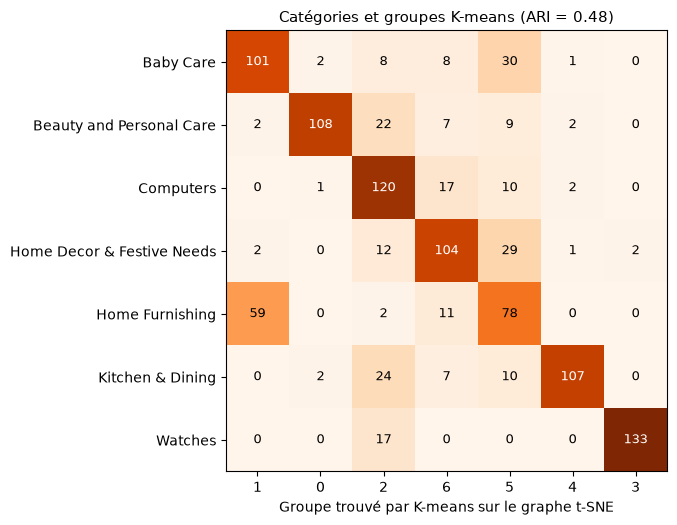

In [11]:
croise = pd.crosstab(pd.Series(y, name="Vraie catégorie"), pd.Series(clusters, name="Groupe K-means"))
croise = croise[croise.idxmax(axis=0).map({c: i for i, c in enumerate(CATEGORIES)}).sort_values().index]

fig, ax = plt.subplots(figsize=(1.0 * len(CATEGORIES) + 3, 0.55 * len(CATEGORIES) + 1.5))
im = ax.imshow(croise.values, cmap="Oranges")
ax.set_xticks(range(croise.shape[1]), croise.columns)
ax.set_yticks(range(croise.shape[0]), croise.index)
for i in range(croise.shape[0]):
    for j in range(croise.shape[1]):
        v = croise.values[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=9,
                color="white" if v > croise.values.max() * 0.6 else "black")
ax.set_xlabel("Groupe trouvé par K-means sur le graphe t-SNE")
ax.set_title(f"Catégories et groupes K-means (ARI = {ari:.2f})", fontsize=11)
plt.tight_layout()
sauver_figure("kmeans_vs_categories.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Comparaison des méthodes de réduction : PCA, t-SNE et UMAP

La consigne laisse le choix entre t-SNE, PCA et UMAP. On projette ici **les mêmes 512 caractéristiques VGG19** avec les trois méthodes,
et on place les graphes côte à côte avec les mêmes couleurs :

- **PCA** (analyse en composantes principales) : projection *linéaire* sur les deux directions de plus grande variance ;
- **t-SNE** : les réglages de la section 4 (ACP à 50 composantes, perplexité 30), on réutilise directement `X_2d` ;
- **UMAP** (*Uniform Manifold Approximation and Projection*) : comme t-SNE, il cherche à garder les voisins proches,
  avec `n_neighbors=15`, `min_dist=0.1`. On lui donne la même entrée que t-SNE (les 50 composantes de l'ACP).

Pour chaque projection, on calcule les trois mesures de la section 5 : pureté du voisinage, ARI de K-means et silhouette.

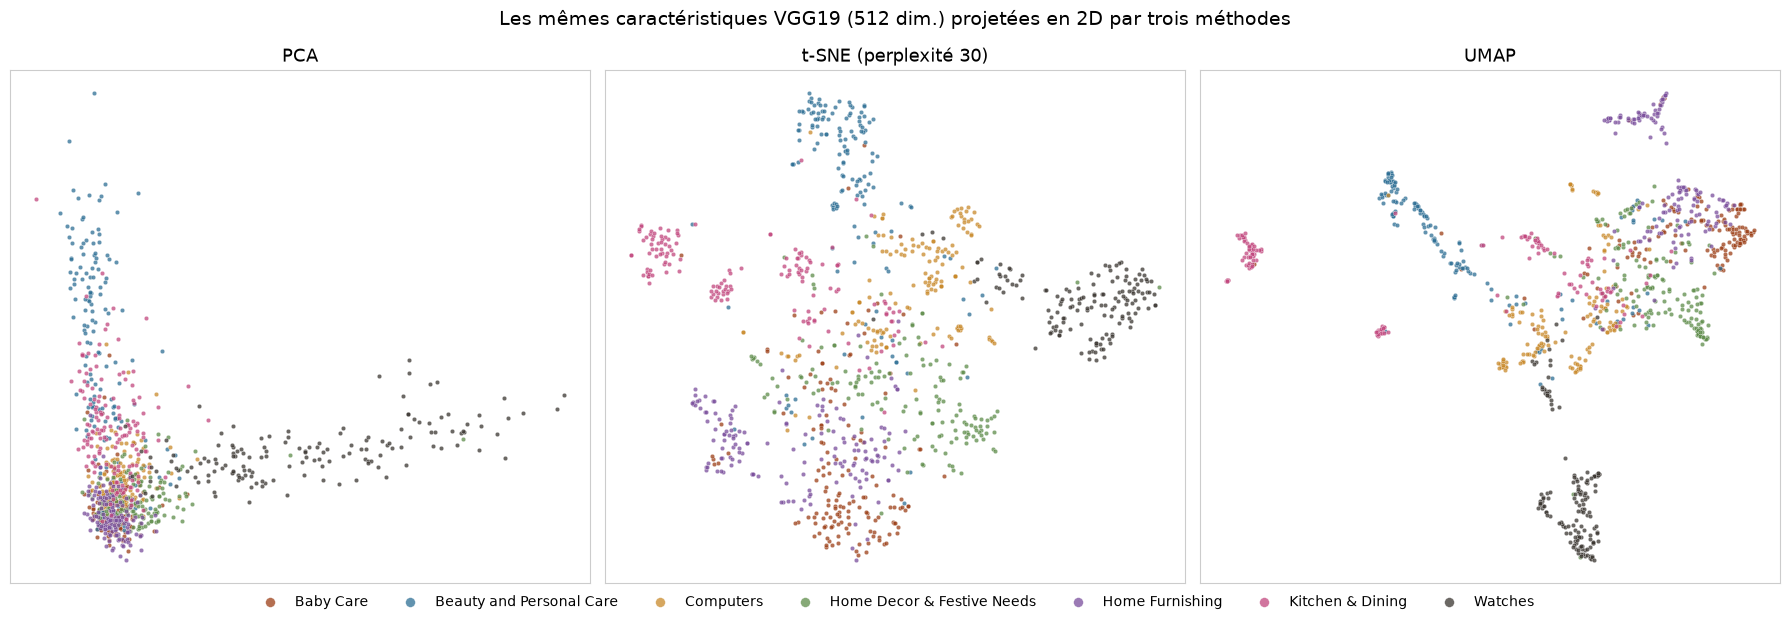

Hasard pour la pureté du voisinage : 14.3%


,pureté du voisinage,ARI (K-means),silhouette
PCA,45.6%,0.215,-0.026
t-SNE (perplexité 30),74.6%,0.482,0.217
UMAP,73.5%,0.388,0.166


In [12]:
import umap   # pip install umap-learn

def evaluer_projection(P, labels=None, k_voisins=10):
    """Pureté du voisinage (10 voisins), ARI K-means et silhouette d'une projection 2D."""
    labels = y if labels is None else labels
    _, vois = NearestNeighbors(n_neighbors=k_voisins + 1).fit(P).kneighbors(P)
    pur = (labels[vois[:, 1:]] == labels[:, None]).mean()
    grp = KMeans(n_clusters=len(CATEGORIES), n_init=10, random_state=SEED).fit_predict(P)
    return {"pureté du voisinage": pur,
            "ARI (K-means)": adjusted_rand_score(labels, grp),
            "silhouette": silhouette_score(P, labels)}

projections = {
    "PCA": PCA(n_components=2, random_state=SEED).fit_transform(X),
    "t-SNE (perplexité 30)": X_2d,
    "UMAP": umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED, n_jobs=1,
                      compatibility_layout=True).fit_transform(X_pca),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (nom, P) in zip(axes, projections.items()):
    for cat in CATEGORIES:
        m = y == cat
        ax.scatter(P[m, 0], P[m, 1], s=10, alpha=0.75, color=couleurs[cat],
                   edgecolors="white", linewidths=0.25, label=cat)
    ax.set_title(nom, fontsize=13)
    ax.set_xticks([]); ax.set_yticks([])
    for cote in ax.spines.values():
        cote.set_color("#cccccc")
poignees, noms = axes[0].get_legend_handles_labels()
fig.legend(poignees, noms, loc="lower center", ncol=len(CATEGORIES), frameon=False,
           fontsize=10, markerscale=2.2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Les mêmes caractéristiques VGG19 (512 dim.) projetées en 2D par trois méthodes", fontsize=14)
plt.tight_layout()
sauver_figure("comparaison_projections.png", dpi=200, bbox_inches="tight")
plt.show()

comparaison = pd.DataFrame({nom: evaluer_projection(P) for nom, P in projections.items()}).T
print(f"Hasard pour la pureté du voisinage : {1 / len(CATEGORIES):.1%}")
comparaison.style.format({"pureté du voisinage": "{:.1%}", "ARI (K-means)": "{:.3f}", "silhouette": "{:.3f}"})

**Pourquoi PCA sépare moins bien.** La PCA est une projection linéaire : elle garde les deux directions où les images varient le plus *globalement*,
et ces directions traduisent surtout des différences générales (luminosité, quantité de fond blanc, taille de l'objet) plutôt que la catégorie.
Avec seulement 2 axes sur 512, les catégories s'écrasent les unes sur les autres. t-SNE et UMAP ne cherchent pas à garder les grandes distances :
ils placent côte à côte les images qui étaient voisines en 512 dimensions, et c'est justement ce voisinage local qui porte l'information de catégorie.

## 7. Stabilité du t-SNE : effet de la perplexité

Le graphe t-SNE dépend de la **perplexité**, à peu près le nombre de voisins pris en compte pour chaque point.
Si les blocs observés n'apparaissaient qu'avec une seule valeur, on pourrait soupçonner un artefact du réglage.
On relance donc t-SNE avec des perplexités de 5, 30 et 50, avec la même graine, et on compare.

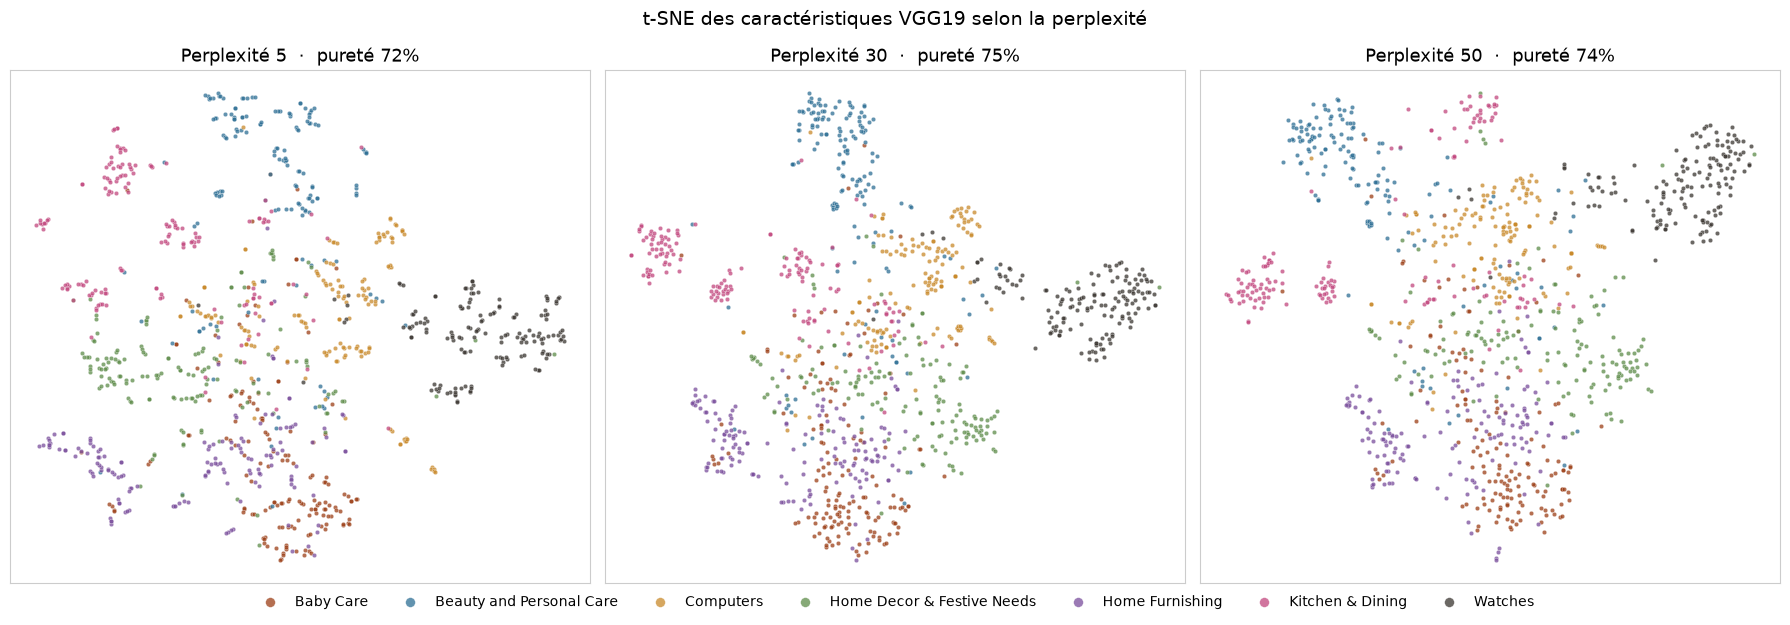

,pureté du voisinage,ARI (K-means),silhouette
perplexité 5,72.0%,0.424,0.163
perplexité 30,74.6%,0.482,0.217
perplexité 50,73.9%,0.436,0.174


In [13]:
perplexites = [5, 30, 50]
tsne_par_perplexite = {}
for p in perplexites:
    if p == perplexite:
        tsne_par_perplexite[p] = X_2d          # déjà calculé en section 4
    else:
        tsne_par_perplexite[p] = TSNE(n_components=2, perplexity=p, init="pca", learning_rate="auto",
                                      random_state=SEED).fit_transform(X_pca)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
stabilite = {}
for ax, (p, P) in zip(axes, tsne_par_perplexite.items()):
    stabilite[f"perplexité {p}"] = evaluer_projection(P)
    for cat in CATEGORIES:
        m = y == cat
        ax.scatter(P[m, 0], P[m, 1], s=10, alpha=0.75, color=couleurs[cat],
                   edgecolors="white", linewidths=0.25, label=cat)
    ax.set_title(f"Perplexité {p}  ·  pureté {stabilite[f'perplexité {p}']['pureté du voisinage']:.0%}", fontsize=13)
    ax.set_xticks([]); ax.set_yticks([])
    for cote in ax.spines.values():
        cote.set_color("#cccccc")
poignees, noms = axes[0].get_legend_handles_labels()
fig.legend(poignees, noms, loc="lower center", ncol=len(CATEGORIES), frameon=False,
           fontsize=10, markerscale=2.2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("t-SNE des caractéristiques VGG19 selon la perplexité", fontsize=14)
plt.tight_layout()
sauver_figure("tsne_perplexites.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame(stabilite).T.style.format({"pureté du voisinage": "{:.1%}", "ARI (K-means)": "{:.3f}", "silhouette": "{:.3f}"})

## 8. Analyse par catégorie

Les mesures globales cachent des différences entre catégories. On regarde ici trois choses :

1. la **pureté du voisinage par catégorie** (sur le t-SNE de la section 4), de la meilleure à la moins bonne ;
2. la **matrice de confusion** de la régression logistique, obtenue par validation croisée à 5 plis (`cross_val_predict`) :
   chaque image est prédite par un modèle qui ne l'a pas vue pendant l'entraînement. La ligne donne la vraie catégorie, la colonne la catégorie prédite ;
3. des **images mal placées** : moins de la moitié de leurs 10 plus proches voisins sur le graphe t-SNE sont de leur catégorie,
   et une autre catégorie domine autour d'elles.

In [14]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

# 1. Pureté du voisinage par catégorie (t-SNE perplexité 30, 10 voisins : variables de la section 5)
purete_cat = pd.Series(purete).groupby(y).mean().sort_values(ascending=False)
print("Pureté du voisinage par catégorie (hasard ≈ {:.0%}) :".format(1 / len(CATEGORIES)))
for cat, v in purete_cat.items():
    print(f"   {cat:<28} {v:6.1%}  {'█' * int(round(v * 30))}")
print(f"\nMeilleure : {purete_cat.index[0]} ({purete_cat.iloc[0]:.1%})   ·   "
      f"moins bonne : {purete_cat.index[-1]} ({purete_cat.iloc[-1]:.1%})")

# 2. Matrice de confusion en validation croisée (même classifieur et mêmes plis que la section 5)
y_pred = cross_val_predict(clf, X, y, cv=cv)
print(f"\nPrécision globale en validation croisée : {(y_pred == y).mean():.1%}\n")
print(classification_report(y, y_pred, digits=3))

Pureté du voisinage par catégorie (hasard ≈ 14%) :
   Watches                       94.4%  ████████████████████████████
   Kitchen & Dining              82.9%  █████████████████████████
   Computers                     74.7%  ██████████████████████
   Beauty and Personal Care      72.9%  ██████████████████████
   Home Decor & Festive Needs    69.0%  █████████████████████
   Home Furnishing               68.1%  ████████████████████
   Baby Care                     60.2%  ██████████████████

Meilleure : Watches (94.4%)   ·   moins bonne : Baby Care (60.2%)



Précision globale en validation croisée : 82.3%

                            precision    recall  f1-score   support

                 Baby Care      0.729     0.700     0.714       150
  Beauty and Personal Care      0.863     0.800     0.830       150
                 Computers      0.832     0.893     0.862       150
Home Decor & Festive Needs      0.769     0.753     0.761       150
           Home Furnishing      0.742     0.787     0.764       150
          Kitchen & Dining      0.879     0.873     0.876       150
                   Watches      0.947     0.953     0.950       150

                  accuracy                          0.823      1050
                 macro avg      0.823     0.823     0.823      1050
              weighted avg      0.823     0.823     0.823      1050



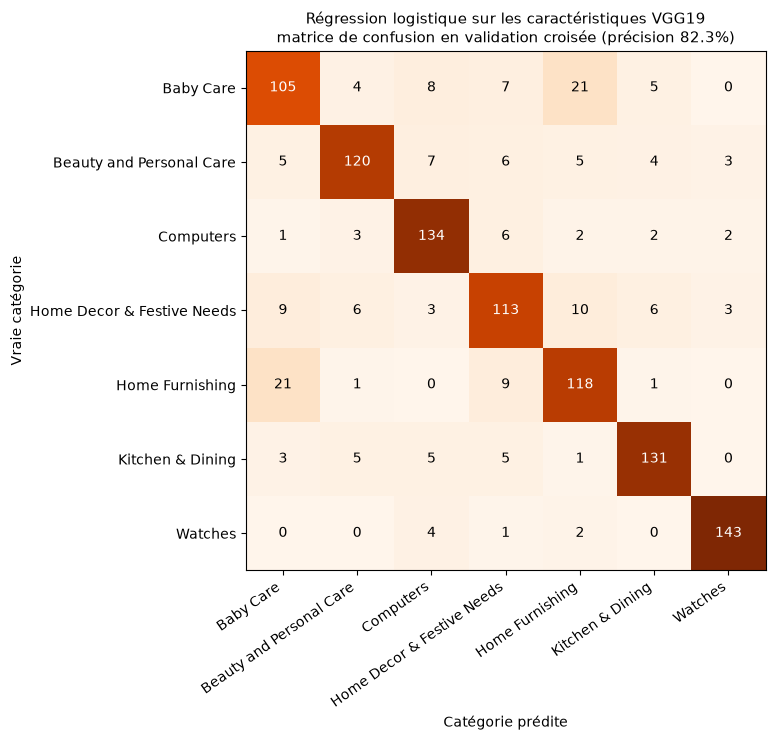

nombre d'images
vraie catégorie            prédite comme                              
Baby Care                  Home Furnishing                          21
Home Furnishing            Baby Care                                21
Home Decor & Festive Needs Home Furnishing                          10
                           Baby Care                                 9
Home Furnishing            Home Decor & Festive Needs                9
Baby Care                  Computers                                 8

In [15]:
mc = confusion_matrix(y, y_pred, labels=CATEGORIES)
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(mc, cmap="Oranges")
ax.set_xticks(range(len(CATEGORIES)), CATEGORIES, rotation=35, ha="right")
ax.set_yticks(range(len(CATEGORIES)), CATEGORIES)
for i in range(len(CATEGORIES)):
    for j in range(len(CATEGORIES)):
        ax.text(j, i, mc[i, j], ha="center", va="center", fontsize=10,
                color="white" if mc[i, j] > mc.max() * 0.6 else "black")
ax.set_xlabel("Catégorie prédite"); ax.set_ylabel("Vraie catégorie")
ax.set_title(f"Régression logistique sur les caractéristiques VGG19\n"
             f"matrice de confusion en validation croisée (précision {(y_pred == y).mean():.1%})", fontsize=11)
plt.tight_layout()
sauver_figure("matrice_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

# Confusions les plus fréquentes (hors diagonale)
confusions = (pd.DataFrame(mc, index=CATEGORIES, columns=CATEGORIES).stack()
                .rename_axis(["vraie catégorie", "prédite comme"]).rename("nombre d'images"))
confusions = confusions[confusions.index.get_level_values(0) != confusions.index.get_level_values(1)]
confusions.sort_values(ascending=False).head(6).to_frame()

Voici maintenant des images **mal placées** sur le graphe t-SNE : moins de la moitié de leurs 10 plus proches voisins sont de leur catégorie,
et une autre catégorie domine autour d'elles.
Sous chaque image : sa vraie catégorie (en couleur) et la catégorie majoritaire autour d'elle.

174 images sur 1050 (16.6%) sont entourées surtout par une autre catégorie que la leur.
entourée surtout de         Baby Care  Beauty and Personal Care  Computers  Home Decor & Festive Needs  Home Furnishing  Kitchen & Dining  Watches
vraie catégorie                                                                                                                                   
Baby Care                           0                         3          5                          14               20                 6        0
Beauty and Personal Care            2                         0         15                           4                3                 5        2
Computers                           2                         2          0                           6                1                 2        1
Home Decor & Festive Needs         12                         5          6                           0                3                 5        2
Home Furnishing               

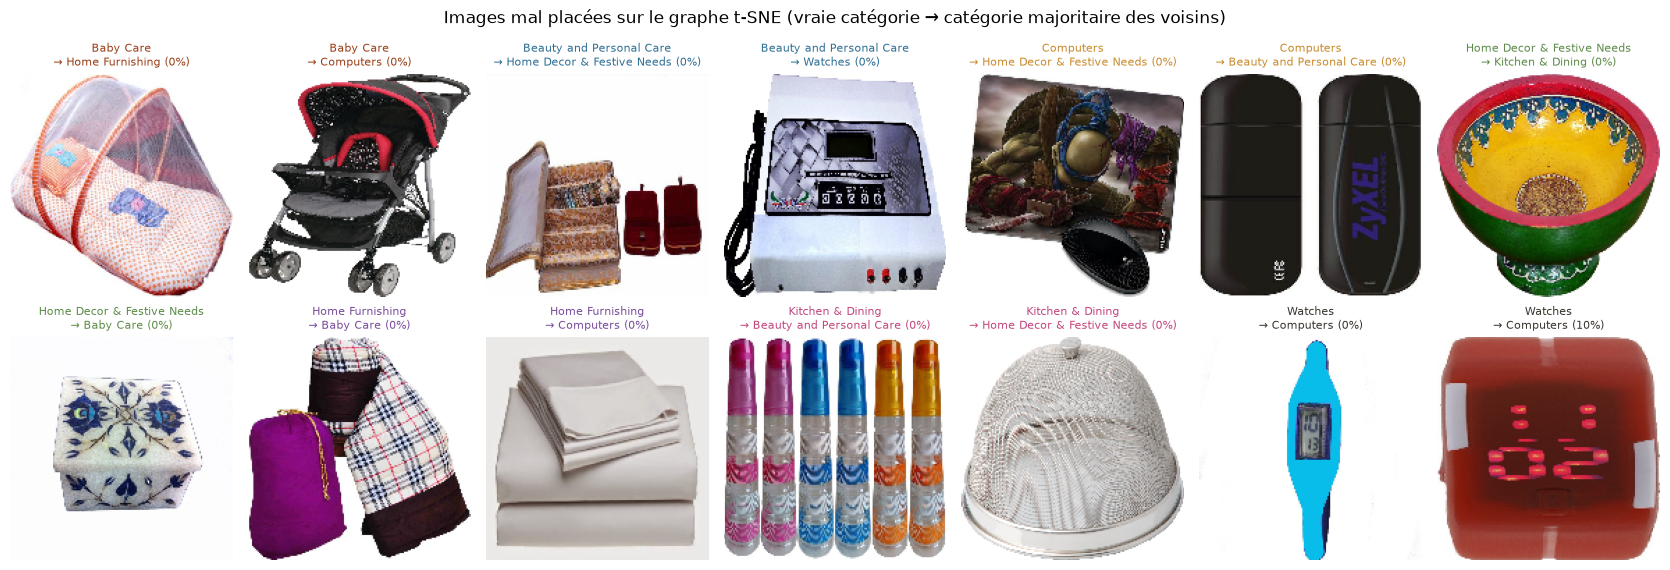


Noms de quelques produits mal placés :
   [Baby Care → Home Furnishing]  CHINMAY KIDS Printed Cotton Padded Mosquito Net
   [Baby Care → Computers]  Graco LiteRider Click Connect � Marco
   [Beauty and Personal Care → Home Decor & Festive Needs]  Kuber Industries Bangle Four Roll & Ring & Earing Box Jewellery Vanity Pouc
   [Beauty and Personal Care → Watches]  SOS COMPUTRISED LCD INTRFERENTIAL UNIT-125PROG. MUSCLE SPASM Electrotherapy
   [Computers → Home Decor & Festive Needs]  FRENEMY MPAD271 Mousepad
   [Computers → Beauty and Personal Care]  Zyxel 3D 1440 - 3G Data Card
   [Home Decor & Festive Needs → Kitchen & Dining]  Purpledip Showpiece  -  12 cm
   [Home Decor & Festive Needs → Baby Care]  Unique Handicrafts Inlaid Marble Box Showpiece  -  4.5 cm
   [Home Furnishing → Baby Care]  Artisan Creation Checkered Single Quilts & Comforters Brown
   [Home Furnishing → Computers]  SRP Linen Cotton Plain King sized Double Bedsheet
   [Kitchen & Dining → Beauty and Personal Care]  Garn

In [16]:
cat_voisins = y[voisins[:, 1:]]
majoritaire = np.array([pd.Series(v).mode().iloc[0] for v in cat_voisins])
# mal placée = moins de la moitié des voisins de sa catégorie ET une autre catégorie dominante autour d'elle
mal_places = np.where((purete < 0.5) & (majoritaire != y))[0]
print(f"{len(mal_places)} images sur {len(y)} ({len(mal_places) / len(y):.1%}) sont entourées surtout par une autre catégorie que la leur.")
print(pd.crosstab(pd.Series(y[mal_places], name="vraie catégorie"),
                  pd.Series(majoritaire[mal_places], name="entourée surtout de")).to_string())

# Échantillon reproductible : jusqu'à 2 images par catégorie, les plus isolées d'abord
echantillon = []
for cat in CATEGORIES:
    idx_cat = [i for i in mal_places[np.argsort(purete[mal_places])] if y[i] == cat]
    echantillon += idx_cat[:2]

n_col = 7
n_lig = int(np.ceil(len(echantillon) / n_col))
fig, axes = plt.subplots(n_lig, n_col, figsize=(2.4 * n_col, 3.0 * n_lig))
for ax in np.atleast_1d(axes).ravel():
    ax.axis("off")
for ax, i in zip(np.atleast_1d(axes).ravel(), echantillon):
    ax.imshow(keras.utils.load_img(df.loc[i, "chemin"], target_size=(160, 160)))
    ax.set_title(f"{y[i]}\n→ {majoritaire[i]} ({purete[i]:.0%})", fontsize=8, color=couleurs[y[i]])
fig.suptitle("Images mal placées sur le graphe t-SNE (vraie catégorie → catégorie majoritaire des voisins)", fontsize=12)
plt.tight_layout()
sauver_figure("images_mal_placees.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nNoms de quelques produits mal placés :")
for i in echantillon:
    print(f"   [{y[i]} → {majoritaire[i]}]  {str(df.loc[i, 'product_name'])[:75]}")

## 9. Commentaire

Les résultats ci-dessous ont été obtenus avec `random_state = 42` sur les 1 050 images (7 catégories de 150), à partir des caractéristiques VGG19 de la section 3.

### Ce que montrent les graphes

Sur le t-SNE de la section 4, trois catégories se détachent nettement. Les **montres** (Watches) forment un bloc presque pur à l'écart de tout le reste : 94 % des voisins d'une montre sont des montres. C'est logique quand on regarde les vignettes : cadran rond, aiguilles, bracelet, toujours photographiés de face sur fond blanc. Un motif aussi régulier correspond très bien aux formes que VGG19 a appris à reconnaître sur ImageNet. **Kitchen & Dining** (83 %) forme lui aussi des îlots bien séparés à gauche du graphe. En regardant de plus près, on comprend pourquoi il y en a plusieurs : la moitié de la catégorie (74 produits sur 150) sont des **mugs**, très semblables entre eux, et le réseau les regroupe à part des casseroles et des bouteilles. **Beauty and Personal Care** (73 %) occupe le haut du graphe, avec ses flacons, déodorants et tubes de crème, tous des objets cylindriques et verticaux.

**Computers** (75 %) forme un groupe reconnaissable, mais éclaté en plusieurs morceaux, parce que la catégorie mélange des objets qui ne se ressemblent pas : routeurs, clés USB, batteries d'ordinateur portable, souris, adaptateurs. Le réseau voit des objets différents, et il a raison.

Le bas du graphe, en revanche, est franchement mélangé. **Baby Care** (60 %, la moins bonne catégorie), **Home Furnishing** (68 %) et **Home Decor & Festive Needs** (69 %) s'y recouvrent. La matrice de confusion confirme que la confusion principale est symétrique : 21 articles Baby Care sont prédits Home Furnishing, et 21 articles Home Furnishing sont prédits Baby Care. Les vignettes l'expliquent bien : dans les deux catégories, on trouve surtout du **textile** photographié à plat ou plié sur fond blanc (vêtements d'enfant, couvertures, housses de coussin, couettes). On trouve même des serviettes de bain dans les deux catégories (11 dans Baby Care, 19 dans Home Furnishing). Pour ces produits, la catégorie dépend de l'usage et non de l'apparence, et VGG19 ne voit que l'apparence. Home Decor est surtout composé de statuettes décoratives (101 « showpieces » sur 150), qui forment un petit groupe à droite, mais le reste (cadres, boîtes, objets peints) se disperse vers les autres catégories.

Les images mal placées de la section 8 (174 sur 1 050, soit 16,6 %) vont dans le même sens. Il s'agit presque toujours d'erreurs compréhensibles, pas d'erreurs absurdes :
- deux montres numériques, sans cadran ni aiguilles, tombent au milieu de l'électronique ;
- des clés 3G noires et cylindriques se retrouvent parmi les flacons de déodorant ;
- un tapis de souris imprimé d'une illustration est placé près des tableaux décoratifs ;
- une moustiquaire pour bébé est rangée avec le linge de maison ;
- une cloche grillagée de cuisine est placée parmi les objets de décoration.

Le réseau regroupe les images par forme, couleur et texture, ce qui est exactement ce pour quoi il a été entraîné.

### Ce que disent les chiffres

Au hasard, un point aurait en moyenne 14 % de voisins de sa catégorie (1 sur 7). Avec le t-SNE, on obtient **74,6 %**, plus de cinq fois mieux. L'ARI de K-means (**0,48**) et la silhouette (**0,22**) restent modérés. Ils traduisent ce qu'on voit à l'œil : des blocs nets pour quatre catégories et une zone de recouvrement pour les trois autres. Le chiffre le plus parlant est la précision de la régression logistique entraînée sur les 512 caractéristiques : **82,3 % ± 2,9 %** en validation croisée, contre 14 % au hasard. Ce score varie de 95 % (F1) pour les montres à 71 % pour Baby Care.

La comparaison des méthodes (section 6) montre que le choix de la projection compte beaucoup pour la lecture visuelle. La **PCA** ne donne que 45,6 % de pureté et une silhouette négative (−0,03). Seules les montres et, dans une moindre mesure, les produits de beauté s'étirent le long des deux axes, et tout le reste s'écrase dans un même nuage. C'est attendu : les deux premières composantes captent les plus grandes variations globales entre images, qui ne coïncident pas avec les catégories. **UMAP** donne un résultat proche de t-SNE (73,5 % de pureté, ARI 0,39), avec les mêmes blocs isolés (montres, mugs, beauté). Il isole en plus un petit groupe de Home Furnishing, qui correspond sur le t-SNE aux parures de lit photographiées dans une chambre, et il garde le même mélange entre Baby Care, Home Furnishing et Home Decor. Deux méthodes différentes qui conservent le voisinage local montrent la même structure : c'est rassurant.

La section 7 répond à une autre inquiétude : les blocs ne dépendent pas du réglage du t-SNE. Avec des perplexités de 5, 30 et 50, la pureté reste entre 72 % et 75 % et les mêmes groupes réapparaissent (montres à droite, mugs à gauche, beauté en haut, textiles en bas). Une perplexité de 5 fragmente simplement chaque catégorie en petits îlots, et 50 les arrondit un peu plus.

### Conclusion

À la question posée par la consigne, des blocs distincts ou des couleurs mélangées, la réponse est : **des blocs distincts pour la majorité des catégories, avec une zone de mélange bien identifiée**. VGG19 privé de ses couches entièrement connectées fournit donc des caractéristiques **exploitables pour classer ces produits**. Le modèle ne s'utilise cependant pas tel quel, puisqu'il ne produit qu'un vecteur de 512 nombres. Il faut lui ajouter un classifieur. Une simple régression logistique suffit déjà à atteindre 82 % sans réentraîner une seule couche du réseau, ce qui est un bon résultat pour un modèle qui n'a jamais vu de produits Flipkart.

Pour aller plus loin, plusieurs pistes sont possibles :
- remplacer la régression logistique par une petite couche dense entraînée sur ces caractéristiques ;
- faire un **ajustement fin (fine-tuning) du bloc 5** de VGG19, avec un taux d'apprentissage faible, pour que les derniers filtres s'adaptent aux produits plutôt qu'aux objets d'ImageNet ;
- utiliser l'**augmentation des données** (retournements, recadrages, variations de luminosité), utile avec seulement 150 images par catégorie pour limiter le surapprentissage pendant ce fine-tuning.

Il faut toutefois garder en tête qu'une partie de la confusion entre Baby Care et Home Furnishing ne vient pas du modèle mais des étiquettes elles-mêmes, puisqu'un même type d'objet (serviettes, couvertures) apparaît dans les deux catégories. Aucun réseau d'images ne pourra lever entièrement cette ambiguïté. Le texte de la description du produit, qui fait partie du même jeu de données, serait le meilleur complément.

### Limite de la visualisation

t-SNE ne conserve que le **voisinage local** : il place côte à côte les images proches, mais la distance entre deux groupes éloignés et la taille des groupes ne veulent rien dire. Surtout, compresser 512 dimensions en 2 fait forcément perdre de l'information. Un mélange de couleurs sur le graphe ne prouve donc pas que les catégories sont inséparables dans l'espace d'origine. C'est précisément ce que montre la régression logistique : elle travaille sur les 512 dimensions et atteint 82 % de bonnes réponses, alors que le graphe 2D laisse penser que Baby Care et Home Furnishing sont presque indiscernables. Le graphe sert à comprendre et à expliquer. Pour juger si le modèle est utilisable, c'est la précision du classifieur qui tranche.